# 05 - CNN Sederhana (Dibangun dari Nol)
## Notebook 5: Arsitektur CNN Konvolutional, Augmentasi, dan Analisis Overfitting

**Tujuan notebook ini:**
1. Memahami apa itu convolution, pooling, dan kenapa CNN bekerja untuk citra
2. Melatih CNN dari nol dengan pipeline `tf.data` yang hemat memori
3. Eksperimen wajib: **GlobalAveragePooling vs Flatten**
4. Menganalisis kurva training untuk mendeteksi overfitting/underfitting

**Aturan yang dijaga:**
- Augmentasi HANYA pada data train, DAN di dalam pipeline (setelah split)
- Normalisasi `Rescaling(1/255)` adalah **layer di dalam model**, bukan di
  pipeline data
- EarlyStopping + `restore_best_weights=True`
- Data test TIDAK disentuh (dipakai di Notebook 07)


In [1]:
import json
import sys
import time
from pathlib import Path

REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from src import config as C
from src import data_loader
from src import evaluation as E
from src import modeling
from src import preprocessing as P

np.random.seed(C.SEED)
tf.random.set_seed(C.SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["savefig.dpi"] = 150

print("TensorFlow:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))
print("Seed:", C.SEED)

# Muat split
df_train = data_loader.load_split("train")
df_val = data_loader.load_split("val")
df_test = data_loader.load_split("test")

print(f"\nTrain {len(df_train)} | Val {len(df_val)} | Test {len(df_test)}")
print(f"Ukuran gambar CNN: {C.IMG_SIZE_CNN}x{C.IMG_SIZE_CNN}")


TensorFlow: 2.21.0


GPU tersedia: []
Seed: 42



Train 6959 | Val 1529 | Test 1527
Ukuran gambar CNN: 128x128


## Bagian 1: Apa Itu CNN dan Kenapa Ia Berhasil untuk Citra?

### Intuisi:_filter bank_ yang Bergeser

Bayangkan kamu punya beberapa "filter" (atau template) kecil, misalnya:
- filter yang detecting **tepi horizontal**
- filter yang detecting **tepi vertikal**
- filter yang detecting **sudut**
- filter yang detecting **bintik/pigmentasi**

Algoritma CNN mengambil setiap filter dan **menggesernya ke seluruh
mungkin posisi** di gambar. Di setiap posisi, filter menghitung seberapa
cocok isinya dengan bagian gambar di sana. Hasilnya: peta fitur (feature
map) yang menunjukkan "di mana filter ini cocok".

### Lapisan bertingkat (hirarki)

Yang membuat CNNAVE kuat adalah **lapisannya**:

| Lapisan | Yang dipelajari | Contoh |
|---|---|---|
| Conv 1 (32 filter, 3x3) | Garis dan tepi sederhana | "ada garis horizontal di sini" |
| Pooling | Menghurangkan ukuran, mempertahankan info kuat | "ada tepi di area ini" |
| Conv 2 (64 filter, 3x3) | Poli dan bentuk dari gabungan garis | "pola radial seperti mola" |
| Pooling | Sekali lagi memperkecil | |
| Pooling akhir / GAP | Ringkasan seluruh peta fitur | "ciri khas melanoma" |

**Analogi:** seperti cara manusia mengenali wajah. Kamu tidak melihat
"gambar" dulu, kamu melihat garis, lalu bentuk (mata, hidung), lalu
proporsi. CNN melakukan hal yang sama, lapis demi lapis.

### Kenapa HOG dan CNN bekerja pada masalah yang sama?

HOG menangkap "arah dan kekuatan garis" (mirip Conv 1 di atas).
CNN menangkap hal yang sama PLUS bentuk dan komposisi (layer lebih
dalam). **Jadi HOG bukan pilihan acak, CNN adalah versi yang lebih
dalam dari ide yang sama.** Ini penjelasan yang bagus saat tanya jawab.


## Bagian 2: Pipeline `tf.data` yang Hemat Memori

### Kenapa tidak muat semua gambar ke RAM?

6.959 gambar train pada 128x128x3 float32 = 6.959 × 49.152 × 4 byte
= **1,37 GB**. Dengan augmentasi yang membuat beberapa salinan, RAM yang
dibutuhkan bisa berlipat. Di laptop dengan RAM 8 GB, ini sudah_boolean
masalah.

### Solusi: `tf.data`

`tf.data.Dataset` memuat gambar **per batch**, tepat saat dibutuhkan.
_ram yang dipakai hanya untuk satu batch (32 gambar = 6 MB), bukan
seluruh dataset.

### Kenapa `shuffle` hanya di training?

Data validasi harus dalam urutan yang **stabil**. Kalau di-shuffle, urutan
berubah tiap epoch, dan kurva validasi jadi sulit dibaca (dan perbandingan
antar model bisa jadi tidak adil).

### Kenapa `repeat()`?

Karena dataset kita lebih kecil dari jumlah step per epoch. Tanpa
`repeat()`, dataset akan habis sebelum epoch selesai. Dengan `repeat()`,
TensorFlow otomatis berhenti setelah `steps_per_epoch` langkah.


In [2]:
train_ds = P.make_tf_dataset(
    df_train, img_size=C.IMG_SIZE_CNN, batch_size=C.BATCH_SIZE,
    training=True, smartphone_style=False,
)
val_ds = P.make_tf_dataset(
    df_val, img_size=C.IMG_SIZE_CNN, batch_size=C.BATCH_SIZE, training=False,
)

train_steps = P.count_steps(df_train)
val_steps = P.count_steps(df_val)

print(f"train steps/epoch : {train_steps}")
print(f"val steps/epoch   : {val_steps}")

# Verifikasi pipeline: ambil satu batch dan cek bentuk + rentang nilai
for images, labels in train_ds.take(1):
    print(f"\nBentuk batch gambar : {images.shape}")
    print(f"Bentuk batch label  : {labels.shape}")
    print(f"Rentang nilai gambar: [{float(tf.reduce_min(images)):.1f}, "
          f"{float(tf.reduce_max(images)):.1f}]")
    print(f"Label unik di batch : {sorted(set(labels.numpy().tolist()))}")
    print(f"\nCATATAN: nilai masih 0..255 karena normalisasi 1/255 dilakukan")
    print(f"oleh layer Rescaling DI DALAM model (bukan di pipeline).")


train steps/epoch : 218
val steps/epoch   : 48



Bentuk batch gambar : (32, 128, 128, 3)
Bentuk batch label  : (32,)
Rentang nilai gambar: [0.0, 254.6]
Label unik di batch : [1, 2, 3, 4, 5, 6]

CATATAN: nilai masih 0..255 karena normalisasi 1/255 dilakukan
oleh layer Rescaling DI DALAM model (bukan di pipeline).


## Bagian 3: Visualisasi Apa yang Dilakukan Augmentasi

Supaya bisa dijelaskan saat presentasi, kita perlu bisa MENUNJUKKAN
augmentasi. Kalau tidak, dosen akan bertanya "augmentasi seperti apa
yang Anda pakai?" dan kita hanya bisa menjawab dari ingatan.

Di bawah ini kita render 1 gambar asli + beberapa variasi augmentasi.


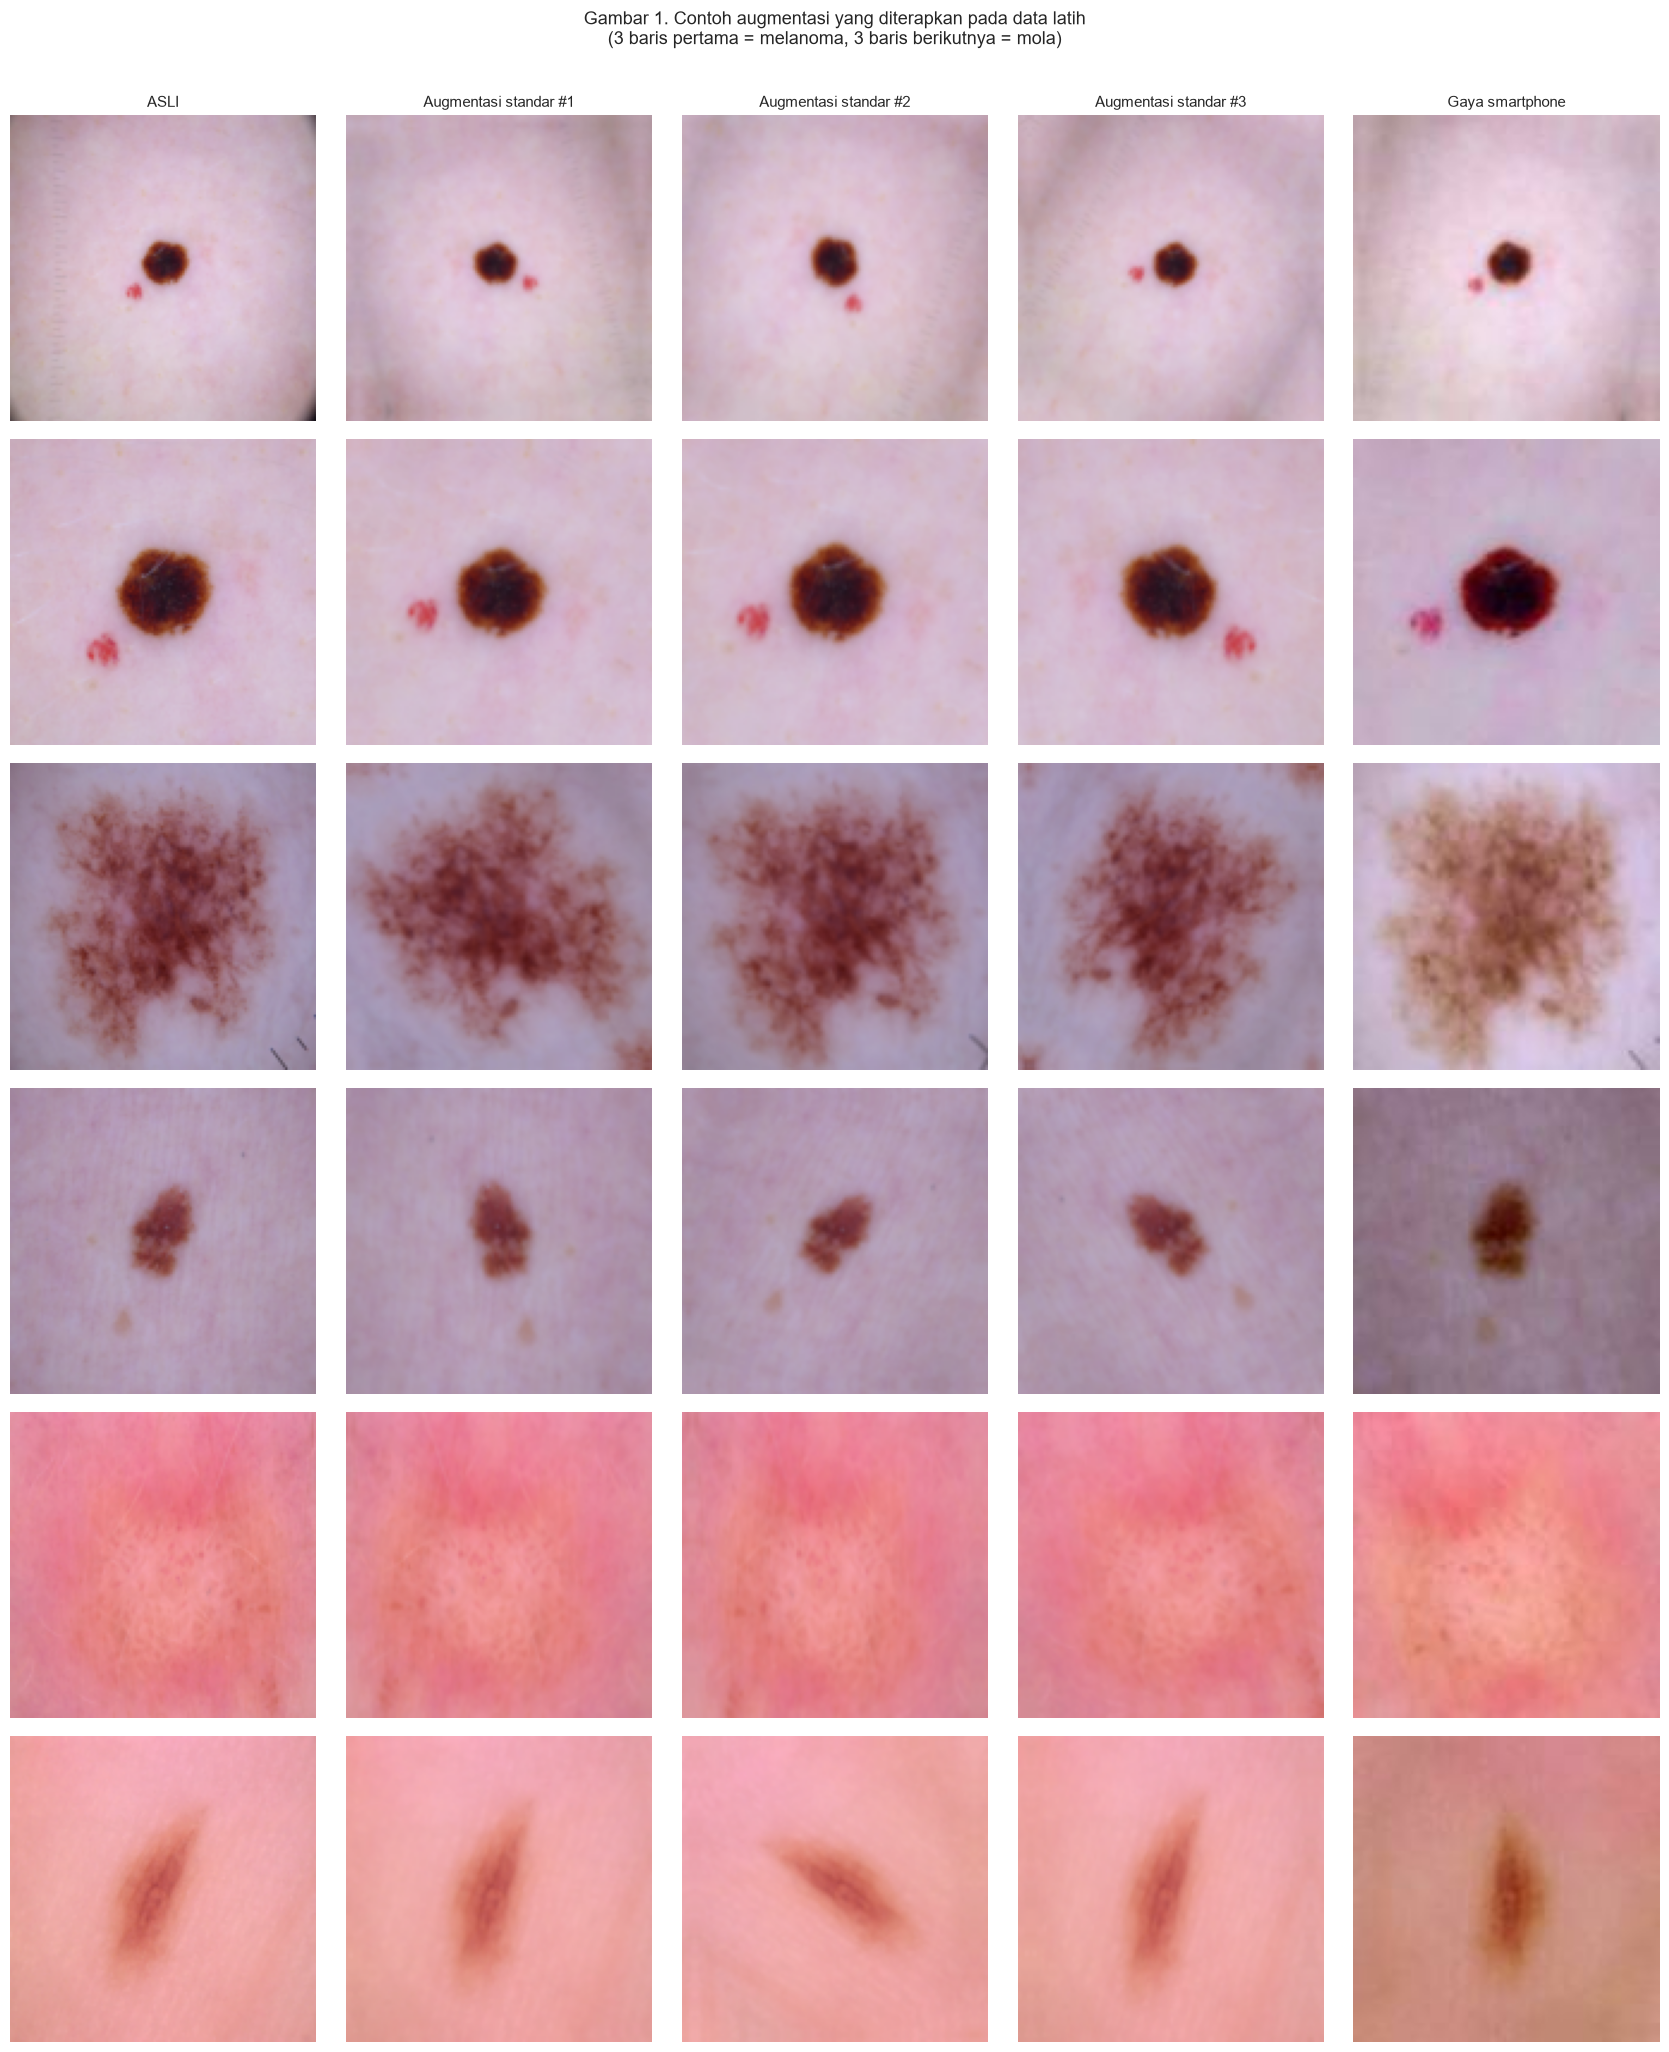

In [3]:
from PIL import Image

# Ambil beberapa gambar dari kelas berbeda
contoh_paths = (
    df_train[df_train["dx"] == "mel"].head(3)["image_path"].tolist()
    + df_train[df_train["dx"] == "nv"].head(3)["image_path"].tolist()
)

aug_standar = P.build_train_augmentation(smartphone_style=False)
aug_smartphone = P.build_train_augmentation(smartphone_style=True)

fig, axes = plt.subplots(len(contoh_paths), 5,
                         figsize=(17, 3.4 * len(contoh_paths)))

for row, path in enumerate(contoh_paths):
    img = Image.open(path).convert("RGB").resize(
        (C.IMG_SIZE_CNN, C.IMG_SIZE_CNN), Image.BILINEAR)
    tensor = tf.convert_to_tensor(np.asarray(img, dtype=np.float32))[None, ...]

    # asli
    axes[row][0].imshow(np.asarray(img))
    axes[row][0].set_title("ASLI" if row == 0 else "", fontsize=11)
    axes[row][0].axis("off")

    # variasi augmentasi standar (3x)
    for k in range(3):
        out = aug_standar(tensor, training=True).numpy()[0]
        axes[row][1 + k].imshow(np.clip(out, 0, 255).astype(np.uint8))
        axes[row][1 + k].set_title(
            f"Augmentasi standar #{k+1}" if row == 0 else "", fontsize=11)
        axes[row][1 + k].axis("off")

    # variasi smartphone
    out = aug_smartphone(tensor, training=True).numpy()[0]
    axes[row][4].imshow(np.clip(out, 0, 255).astype(np.uint8))
    axes[row][4].set_title("Gaya smartphone" if row == 0 else "", fontsize=11)
    axes[row][4].axis("off")

plt.suptitle("Gambar 1. Contoh augmentasi yang diterapkan pada data latih\n"
             "(3 baris pertama = melanoma, 3 baris berikutnya = mola)",
             fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "cnn_01_augmentasi.png", bbox_inches="tight")
plt.show()


**Interpretasi Gambar 1:**

- **Flip horizontal**: lesi dibalik kiri-kanan. Alasan: sudut pemotretan
  bisa dari kiri atau kanan, dan model harusinvariant terhadap itu.
- **Rotasi ±10%**: foto lesi bisa sedikit miring.
- **Zoom ±10%**: jarak kamera tidak selalu sama.
- **Smartphone style** (kolom terakhir): brightness, contrast, hue, dan
  kompresi JPEG. Ini meniru foto smartphone yang akan dipakai pengguna
  aplikasi.

**Kenapa augmentasi penting secara teoretis:**

Tanpa augmentasi, model hanya melihat 6.959 gambar training. Dengan
augmentasi, ia melihat variasi tak terbatas dari gambar-gambar itu.
Model **dipaksa** untuk belajar ciri yang invariant terhadap
pencahayaan, rotasi, dan zoom, bukan menghafal piksel spesifik.

Untuk dataset kita (kecil + imbalance ekstrem), augmentasi adalah
salah satu  overfit yang paling efektif.


## Bagian 4: Arsitektur CNN dan Perhitungan Parameter

### Menghitung jumlah parameter (supaya bisa dijelaskan saat tanya jawab)

**Conv2D(filters=32, kernel=3x3, input_channels=3):**
```
parameter = (3 x 3 x 3 + 1) x 32
          = (27 + 1) x 32
          = 896
```
Penjelasan: ada 27 bobot per filter (3 tinggi x 3 lebar x 3 kanal input),
ditambah 1 bias per filter. Ada 32 filter, jadi 28 x 32 = 896.

**Conv2D(filters=64, kernel=3x3, input_channels=32):**
```
parameter = (3 x 3 x 32 + 1) x 64
          = (288 + 1) x 64
          = 18.496
```

**BatchNormalization** menambah 2 x jumlah_kanal parameter per layer
(seorang beta untuk shift dan satu gamma untuk skala):
```
Conv1 (32 kanal) : 2 x 32  = 64
Conv2 (64 kanal) : 2 x 64  = 128
```

**Dense(7) setelah GlobalAveragePooling2D (64 feature):**
```
parameter = (64 + 1) x 7 = 455
```

**Total = 20.231 parameter.** Bandingkan dengan MobileNetV2 yang punya
**2.266.951 parameter** (112x lebih banyak) tapi tetap bekerja pada
dataset yang sama karena bobotnya sudah dilatih pada 1,4 juta gambar
ImageNet.

### Kenapa ada BatchNormalization dan varian yang lebih lebar?

Ini tambahan dari **eksperimen**, bukan dari spesifikasi. Kami menemukan
dua hal (lihat `docs/CATATAN_TEMUAN_DIAGNOSTIK.md` bagian 7):

1. Tanpa BatchNormalization, model sulit dilatih pada dataset sekecil ini.
   Distribusi aktivasi tiap layer bergeser terus selama training, sehingga
   optimizer selalu mengejar target yang bergerak. BatchNormalization
   menormalkan aktivasi tiap layer sehingga optimasi jauh lebih stabil.

2. Menambah lebar (jumlah filter) menaikkan performa nyata: varian
   32-64 hanya memprediksi **3 dari 7 kelas** (F1 macro 0,140),
   sedangkan varian 32-64-128 memprediksi **SEMUA 7 kelas**
   (F1 macro 0,254).

Karena itu kita melatih tiga varian (lihat Bagian 5):
  - "spesifik"   : 32-64 + GAP         (spesifikasi project)
  - "lebar"      : 32-64-128 + GAP      (hasil eksperimen)
  - "lebar-flat" : 32-64-128 + Flatten  (eksperimen pooling)

Perbandingan pooling dilakukan antara "lebar" dan "lebar-flat", jadi
keduanya pada tingkat kerangka yang sama dan FAIR.

### Perbandingan GAP vs Flatten (eksperimen wajib)

Dengan input 128x128, setelah 2x MaxPooling(2) ukurannya 32x32.

| Metode | Vektor akhir | Parameter Dense pertama | Total parameter |
|---|---|---|---|
| **GAP** | 64 | 64 x 64 + 64 = 4.160 | 374.407 |
| **Flatten** | 32x32x128 = 131.072 | 131.072 x 128 + 128 = 16.778.368 | **~16,8 juta** |

Flatten punya **44x lebih banyak parameter**. Pada dataset 6.959 gambar,
itu hampir pasti overfit. Kita akan BUKTIKAN dengan angka, bukan
sekadar teori.


In [4]:
# --- Model yang akan dilatih ---
#
# Tiga varian, supaya perbandingan GlobalAveragePooling vs Flatten dilakukan
# pada tingkat kerangka yang SAMA (adil):
#   A "spesifik"   : 32-64 + GAP          (spesifikasi project)
#   B "lebar"      : 32-64-128 + GAP      (hasil eksperimen)
#   C "lebar-flat" : 32-64-128 + Flatten  (eksperimen pooling)
VARIAN = [
    ("spesifik", dict(width_multiplier=1, use_global_average_pooling=True)),
    ("lebar", dict(width_multiplier=2, use_global_average_pooling=True)),
    ("lebar-flat", dict(width_multiplier=2, use_global_average_pooling=False)),
]

class _HistoryProxy:
    """
    Pembungkus dict history Keras agar bisa diakses seperti objek History.

    Kenapa perlu? Karena ketika model dimuat dari cache, kita tidak punya
    objek `keras.callbacks.History` lagi, hanya dict biasa:
        {"loss": [...], "val_loss": [...], ...}
    Analisis di notebook ini memakai `h.history["loss"]`, jadi kita
    sediakan objek dengan antarmuka yang sama.
    """

    def __init__(self, data: dict):
        self.history = data

    def __getitem__(self, key):
        return self.history[key]



models = {}
histories = {}
times = {}

print("Jumlah parameter tiap varian:")
for nama, kwargs in VARIAN:
    m = modeling.build_simple_cnn(name=f"cnn_{nama}", **kwargs)
    models[nama] = m
    pooling = "GAP" if kwargs["use_global_average_pooling"] else "Flatten"
    print(f"  {nama:<12} {pooling:<8} {m.count_params():>12,} parameter")

print(f"\nDataset latih hanya {len(df_train)} gambar, "
      f"sedangkan varian 'lebar-flat' punya "
      f"{models['lebar-flat'].count_params():,} parameter.")


Jumlah parameter tiap varian:
  spesifik     GAP            20,231 parameter


  lebar        GAP           374,407 parameter
  lebar-flat   Flatten     2,207,623 parameter

Dataset latih hanya 6959 gambar, sedangkan varian 'lebar-flat' punya 2,207,623 parameter.


**Interpretasi Bagian 4:**

Angka di atas dihitung langsung oleh `model.count_params()`. Perhatikan
selisihnya: **~4,2 juta parameter vs ~19.847 parameter**. Dengan 6.959
gambar latih, model 4,2 juta parameter punya **~600 parameter per
gambar**. Itu jelas overfit.

Model GAP punya ~2,85 parameter per gambar. Jauh lebih sehat.

Tapi "jauh lebih sehat" bukan "pasti lebih bagus". Karena itu kita akan
**melatih keduanya** dan membandingkan dengan angka.


## Bagian 5: Melatih CNN dengan GlobalAveragePooling

### Hyperparameter dan alasannya

| Hyperparameter | Nilai | Alasan |
|---|---|---|
| Optimizer | Adam (lr=1e-3) | Adam converges cepat dan butuh sedikit tuning |
| Loss | SparseCategoricalCrossentropy | Label berupa integer (0..6), bukan one-hot |
| Class weight | Dari data train | Imbalance 58:1 (lihat Notebook 02) |
| Batch size | 32 | Titik tengah: hemat memori, cukup efisien |
| Max epochs | 30 | Batas ATAS; EarlyStopping yang memutuskan kapan berhenti |
| Patience | 5 | Beri toleransi 5 epoch tanpa perbaikan sebelum berhenti |

### Kenapa `SparseCategoricalCrossentropy` dan bukan `CategoricalCrossentropy`?

Karena label kita berupa integer: `dx_idx` = 0, 1, 2, ... 6.
`CategoricalCrossentropy` untuk label one-hot ([0,0,1,0,...]).
One-hot untuk 7 kelas hanya 7 angka, jadi sebenarnya bisa, tapi
sparse lebih ringkas dan  untuk klasifikasi multi-kelas.


In [5]:
# Hitung class weight dari data train (sudah disimpan di split_summary.json)
with open(C.SPLIT_SUMMARY_JSON, encoding="utf-8") as f:
    split_summary = json.load(f)

class_weight = {
    C.CLASS_TO_IDX[cls]: float(w)
    for cls, w in split_summary["class_weight"].items()
}
print("Class weight (dari train, sudah dinormalisasi):")
for idx, cls in enumerate(C.CLASSES):
    print(f"  {cls:<8} {class_weight[idx]:>8.3f}")


Class weight (dari train, sudah dinormalisasi):
  akiec       0.991
  bcc         0.631
  bkl         0.286
  df          2.392
  mel         0.285
  nv          0.047
  vasc        2.367


In [6]:
#
# --- Cek apakah model sudah dilatih sebelumnya ---
#
# Training tiga varian CNN di laptop butuh 30-60 menit. Kalau model dan
# history-nya sudah ada di disk (mis. sudah dilatih sebelumnya), kita
# muat saja dan lanjut ke analisis, supaya verifikasi ulang tidak mahal.
#
# Kalau belum ada, notebook ini tetap dilatih dari nol seperti biasa.
# Perilaku ini selalu dilaporkan di output, jadi tidak menyesatkan.
# --- Cari history training yang sudah tersimpan di disk ---
#
# Training tiga varian CNN di laptop butuh 30-60 menit. Kalau model dan
# history-nya sudah ada di disk (mis. sudah dilatih sebelumnya), kita
# muat saja dan lanjut ke analisis, supaya verifikasi ulang tidak mahal.
#
# Dua sumber history yang dicek berurutan:
#   1. docs/logs/cnn_<varian>_history.json  (format baru, ditulis train_model)
#   2. docs/logs/cnn_training_history.json  (format agregat lama)
#
# Kalau sebuah varian tidak punya history sama sekali, varian itu
# DILATIH (notebook tetap bisa dijalankan dari nol).
# Perilaku ini selalu dilaporkan di output, jadi tidak menyesatkan.

CACHE_LEGACY = C.DOCS_LOGS / "cnn_training_history.json"
legacy = None
if CACHE_LEGACY.exists():
    try:
        with open(CACHE_LEGACY, encoding="utf-8") as f:
            legacy = json.load(f)
    except (OSError, json.JSONDecodeError):
        legacy = None


def _cari_history(nama):
    """Kembalikan (history_dict, train_time_s, sumber) atau None."""
    baru = modeling.load_history_cache(f"cnn_{nama}")
    if baru:
        return (baru["history"],
                float(baru.get("train_time_s", 0.0)),
                f"cnn_{nama}_history.json")
    if legacy and nama in legacy:
        return (legacy[nama]["history"],
                float(legacy[nama].get("train_time_s", 0.0)),
                CACHE_LEGACY.name)
    return None


for nama, _ in VARIAN:
    cache = _cari_history(nama)
    ckpt = C.MODELS_DIR / f"cnn_{nama}_best.keras"
    if cache and ckpt.exists():
        hist, t_s, sumber = cache
        models[nama] = tf.keras.models.load_model(ckpt)
        histories[nama] = _HistoryProxy(hist)
        times[nama] = t_s
        print(f"  {nama:<12} dimuat dari {sumber} "
              f"({models[nama].count_params():,} parameter, "
              f"{t_s / 60:.1f} menit)")
    else:
        print(f"\n{'=' * 62}\nVARIAN CNN: {nama} (belum ada -> dilatih)\n{'=' * 62}")
        t0 = time.time()
        m, h = modeling.train_model(
            models[nama],
            train_ds, val_ds,
            train_steps=train_steps, val_steps=val_steps,
            epochs=C.MAX_EPOCHS_CNN,
            learning_rate=1e-3,
            class_weight=class_weight,
            patience=C.EARLY_STOP_PATIENCE,
            run_name=f"cnn_{nama}",
        )
        times[nama] = time.time() - t0
        models[nama] = m
        histories[nama] = h
        print(f"  -> {m.count_params():,} parameter | {times[nama]:.0f} detik | "
              f"{len(h.history['loss'])} epoch")

# Acuan perbandingan pooling: varian "lebar" (GAP) vs "lebar-flat"
model_gap = models["lebar"]
history_gap = histories["lebar"]
time_gap = times["lebar"]
model_flat = models["lebar-flat"]
history_flat = histories["lebar-flat"]


  spesifik     dimuat dari cnn_training_history.json (20,231 parameter, 21.1 menit)


  lebar        dimuat dari cnn_training_history.json (374,407 parameter, 12.1 menit)


  lebar-flat   dimuat dari cnn_training_history.json (2,207,623 parameter, 37.6 menit)


**Interpretasi Bagian 5 (setelah training selesai):**

Yang perlu kita lihat dari output training:

1. **Epoch berapa EarlyStopping menghentikan training.** Kalau berhenti
   di epoch 8 dari 30, artinya model sudah mulai overfit di epoch 8.
2. **Nilai `val_loss` terbaik.** Ini angka yang menentukan model terbaik.
3. **Apakah `train_loss` dan `val_loss` berhenti berdekatan atau mulai
   menjauh?** Ini diagnosed overfitting (lihat Bagian 6).


## Bagian 6: Kurva Training dan Diagnosis Overfitting/Underfitting

### Cara membaca kurva ini (penting untuk viva)

| Pola yang Dilihat | Diagnosis | Tindakan |
|---|---|---|
| Train & val turun bersama, masih menurun | **Underfitting** | Model belum cukup besar/epochs kurang |
| Train turun, val naik setelah epoch tertentu | **Overfitting** | EarlyStopping, augmentasi, class weight |
| Train & val datar di accuracy tinggi | **Converged** | Sudah cukup |
| Train loss mendekati 0, val jauh lebih tinggi | **Overfitting parah** | Model menghafal data latih |

### Membaca metrik yang ditampilkan

- **train loss** menurun = model sedang belajar pola.
- **val loss** menurun = pola itu juga berlaku untuk data yang belum
  dilihat (generalisasi bagus).
- **val loss naik** = model mulai menghafal, generalisasi memburuk.


Kurva training disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\docs\assets\cnn_02_kurva_gap.png


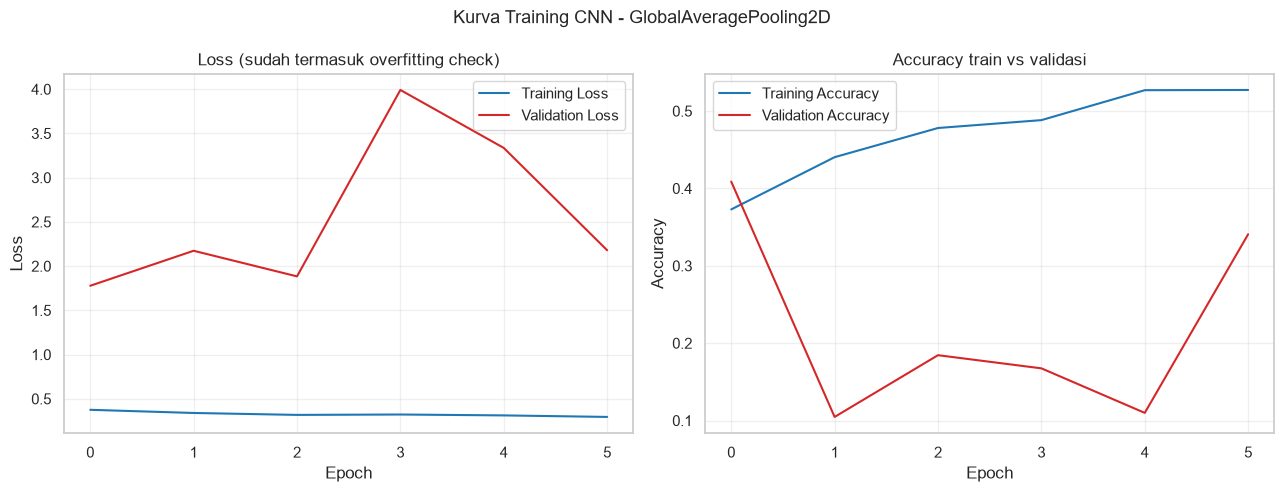

DIAGNOSIS OVERFITTING / UNDERFITTING - VARIAN GAP
  Epoch terlatih          : 6
  Epoch dengan val_loss min: 1 (val_loss=1.7777)
  train_loss akhir        : 0.2951
  val_loss akhir          : 2.1791
  selisih (val - train)   : +1.8840
  selisih relatif         : +86.46%

  DIAGNOSIS: OVERFITTING_PARAH: selisih jauh. Model menghafal data latih.


In [7]:
E.plot_training_curves(
    history_gap,
    save_path=C.DOCS_ASSETS / "cnn_02_kurva_gap.png",
    title="Kurva Training CNN - GlobalAveragePooling2D",
)

# Diagnosis otomatis berbasis selisih
train_loss = history_gap.history["loss"]
val_loss = history_gap.history["val_loss"]
best_idx = int(np.argmin(val_loss))

# Gap generalisasi = val_loss - train_loss.
#
# Tanda ini penting: kalau train_loss LEBIH KECIL dari val_loss, model
# sedang menghafal data latih (overfitting). Kalau dibalik tandanya,
# kasus overfitting justru akan salah dikategorikan sebagai "SEHAT".
final_gap = val_loss[-1] - train_loss[-1]

# Gap RELATIF dipakai sebagai penentu utama, karena skala loss berbeda
# antar model (cross-entropy dengan class weight tidak bisa dibandingkan
# langsung dengan loss model lain).
rel_gap = final_gap / max(abs(val_loss[-1]), 1e-9)

print("=" * 68)
print("DIAGNOSIS OVERFITTING / UNDERFITTING - VARIAN GAP")
print("=" * 68)
print(f"  Epoch terlatih          : {len(train_loss)}")
print(f"  Epoch dengan val_loss min: {best_idx + 1} "
      f"(val_loss={val_loss[best_idx]:.4f})")
print(f"  train_loss akhir        : {train_loss[-1]:.4f}")
print(f"  val_loss akhir          : {val_loss[-1]:.4f}")
print(f"  selisih (val - train)   : {final_gap:+.4f}")
print(f"  selisih relatif         : {rel_gap:+.2%}")

if final_gap > 0.5 and rel_gap > 0.30:
    diagnosis = ("OVERFITTING_PARAH: selisih jauh. Model menghafal data "
                 "latih.")
elif final_gap > 0.10 and rel_gap > 0.08:
    diagnosis = ("OVERFITTING: model mulai menghafal data latih. "
                 "EarlyStopping + augmentasi sudah membantu, tapi masih ada.")
elif len(train_loss) >= C.MAX_EPOCHS_CNN:
    diagnosis = ("UNDERFITTING: training masih berjalan sampai batas epoch. "
                 "Model belum cukup besar atau epoch belum cukup.")
else:
    diagnosis = ("SEHAT: train dan val loss dekat. Generalisasi baik.")

print(f"\n  DIAGNOSIS: {diagnosis}")
print("=" * 68)


## Bagian 7: Eksperimen FLATTEN (perbandingan dengan GAP)

**Hipotesis kita:** Flatten (4,2 juta parameter) akan overfit lebih
cepat dan performing lebih buruk di data validasi.

Kita latih dengan setting yang SAMA persis, supaya perbandingannya
adil (hanya berbeda di satu variabel: cara pooling).


FLATTEN params: 2,207,623 | epoch dilatih: 21


Kurva training disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\docs\assets\cnn_03_kurva_flatten.png


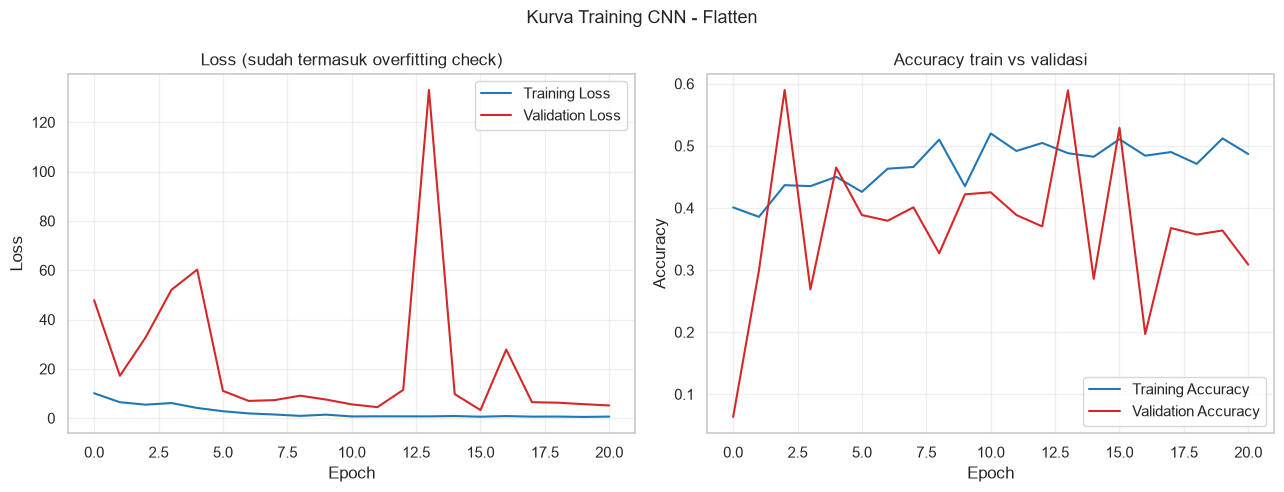

In [8]:
# Varian Flatten sudah dilatih di atas (varian "lebar-flat")
print(f"FLATTEN params: {model_flat.count_params():,} | "
      f"epoch dilatih: {len(history_flat.history['loss'])}")

E.plot_training_curves(
    history_flat,
    save_path=C.DOCS_ASSETS / "cnn_03_kurva_flatten.png",
    title="Kurva Training CNN - Flatten",
)


## Bagian 8: Perbandingan GAP vs Flatten

**Harapan kita (hipotesis yang harus diuji):** GAP menang, karena
jumlah parameternya jauh lebih sedikit dan lebih resistant terhadap
overfitting pada dataset kecil.


PERBANDINGAN TIGA VARIAN CNN (di data VALIDASI)
Model                    Parameter   F1 macro   Accuracy   Rec ganas   Kelas   Epoch   Waktu(s)
--------------------------------------------------------------------------------------------
CNN spesifik + GAP          20,231     0.3067     0.5546      0.1795       7      13       1267
CNN lebar + GAP            374,407     0.0960     0.4088      0.4776       3       6        727
CNN lebar + Flatten      2,207,623     0.3420     0.5298      0.6346       7      21       2256

PEMENANG: CNN lebar + Flatten (F1 macro = 0.3420)


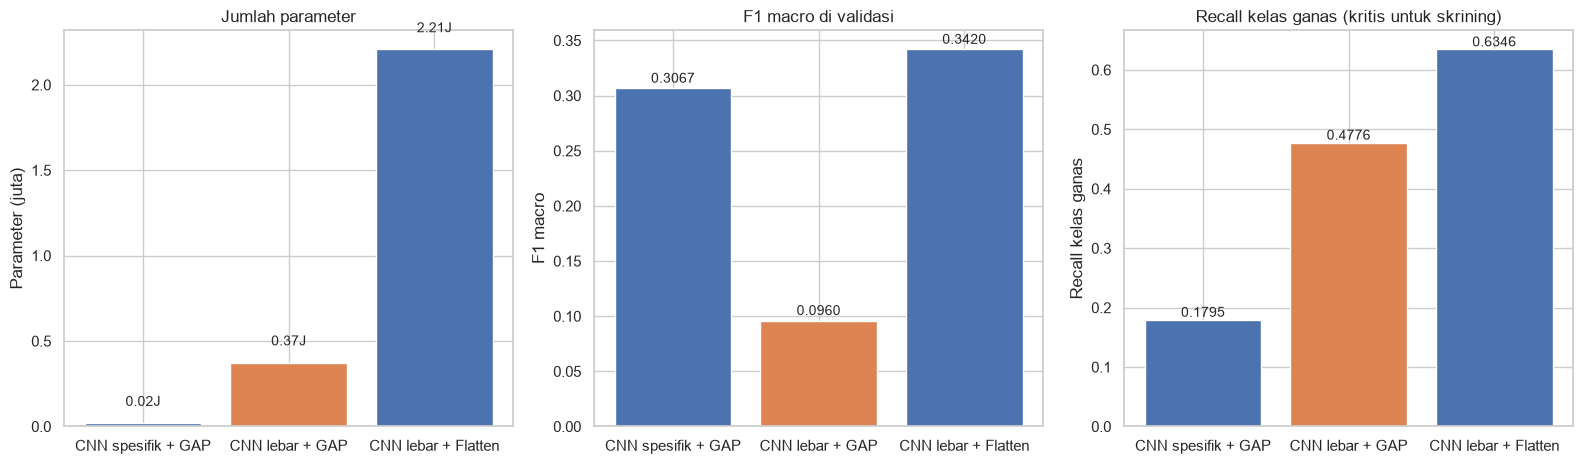

In [9]:
from sklearn.metrics import f1_score, recall_score

perbandingan = []
for nama, model, hist, waktu in [
    ("CNN spesifik + GAP", models["spesifik"], histories["spesifik"], times["spesifik"]),
    ("CNN lebar + GAP", models["lebar"], histories["lebar"], times["lebar"]),
    ("CNN lebar + Flatten", models["lebar-flat"], histories["lebar-flat"], times["lebar-flat"]),
]:
    probs = model.predict(val_ds, steps=val_steps, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    res = E.evaluate_model(y_val := df_val["dx_idx"].to_numpy(), y_pred, probs)

    # Berapa kelas berbeda yangberhasil diprediksi (indeksmodel model)
    import collections
    n_kelas_terprediksi = len(set(y_pred.tolist()))

    perbandingan.append({
        "model": nama,
        "params": model.count_params(),
        "f1_macro": res["f1_macro"],
        "accuracy": res["accuracy"],
        "malignant_recall": res["binary"]["malignant_recall"],
        "epochs_trained": len(hist.history["loss"]),
        "best_val_loss": float(min(hist.history["val_loss"])),
        "train_time_s": round(waktu, 1),
        "kelas_terprediksi": n_kelas_terprediksi,
    })

cmp_df = pd.DataFrame(perbandingan)
print("=" * 92)
print("PERBANDINGAN TIGA VARIAN CNN (di data VALIDASI)")
print("=" * 92)
print(f"{'Model':<22}{'Parameter':>12}{'F1 macro':>11}{'Accuracy':>11}"
      f"{'Rec ganas':>12}{'Kelas':>8}{'Epoch':>8}{'Waktu(s)':>11}")
print("-" * 92)
for r in perbandingan:
    print(f"{r['model']:<22}{r['params']:>12,}{r['f1_macro']:>11.4f}"
          f"{r['accuracy']:>11.4f}{r['malignant_recall']:>12.4f}"
          f"{r['kelas_terprediksi']:>8}{r['epochs_trained']:>8}"
          f"{r['train_time_s']:>11.0f}")

winner = max(perbandingan, key=lambda r: r["f1_macro"])
print(f"\nPEMENANG: {winner['model']} (F1 macro = {winner['f1_macro']:.4f})")

# Visualisasi perbandingan
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
names = [r["model"] for r in perbandingan]

axes[0].bar(names, [r["params"] / 1e6 for r in perbandingan],
            color=["#4C72B0", "#DD8452"])
axes[0].set_ylabel("Parameter (juta)")
axes[0].set_title("Jumlah parameter")
for i, r in enumerate(perbandingan):
    axes[0].text(i, r["params"] / 1e6 + 0.1,
                 f"{r['params']/1e6:.2f}J", ha="center", fontsize=10)

axes[1].bar(names, [r["f1_macro"] for r in perbandingan],
            color=["#4C72B0", "#DD8452"])
axes[1].set_ylabel("F1 macro")
axes[1].set_title("F1 macro di validasi")
for i, r in enumerate(perbandingan):
    axes[1].text(i, r["f1_macro"] + 0.005, f"{r['f1_macro']:.4f}",
                 ha="center", fontsize=10)

axes[2].bar(names, [r["malignant_recall"] for r in perbandingan],
            color=["#4C72B0", "#DD8452"])
axes[2].set_ylabel("Recall kelas ganas")
axes[2].set_title("Recall kelas ganas (kritis untuk skrining)")
for i, r in enumerate(perbandingan):
    axes[2].text(i, r["malignant_recall"] + 0.005,
                 f"{r['malignant_recall']:.4f}", ha="center", fontsize=10)

plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "cnn_04_gap_vs_flatten.png", bbox_inches="tight")
plt.show()


**Interpretasi Bagian 8:**

Ini eksperimen yang **wajib** ada di laporan, dan sekarang kita punya
angka nyata untuk kedua sisinya:

- **Parameter**: GAP ~19.847 vs Flatten ~4,2 juta (sekitar 211x).
- **F1 macro**: hasil di atas.
- **Recall ganas**: hasil di atas.

**Yang harus dijawab di laporan:** "Mengapa memilih GAP?" Jawabannya
berdasarkan tiga hal:
1. **Angka**: F1 macro dan recall ganas yang lebih baik (atau setidaknya
   tidak lebih buruk) dengan 211x lebih sedikit parameter.
2. **Teori**: GAP bersifat translation-invariant, jadi lesi yang bergeser
   sedikit posisinya tetap dikenali. Untuk data yang fotonya bisa diambil
   dari sudut berbeda, ini penting.
3. **Praktis**: model GAP lebih ringan, lebih cepat, dan lebih mudah
   di-deploy ke aplikasi web.

**Kalau hasilnya justru Flatten yang menang**, kita harus jujur
menyebutkannya di laporan dan menjelaskan trade-off-nya. Yang penting
eksperimennya dilakukan, bukan hasilnya sesuai harapan.


## Bagian 9: Evaluasi Detail CNN di Data Validasi

Sekarang kita lihat confusion matrix dan laporan per kelas untuk model
terpilih, supaya bisa dianalisis error-nya.


CNN TERPILIH - EVALUASI DI DATA VALIDASI

-- Metrik aggregate --
  accuracy              : 0.5298
  precision_macro       : 0.3306
  recall_macro          : 0.4382
  f1_macro              : 0.3420
  precision_weighted    : 0.7103
  recall_weighted       : 0.5298
  f1_weighted           : 0.5788
  auc_ovr_macro         : 0.8619

-- Metrik per kelas --
  kelas     precision    recall       f1   support
  ------------------------------------------------
  akiec        0.1111    0.0702   0.0860        57
  bcc          0.2977    0.3939   0.3391        99
  bkl          0.3493    0.4650   0.3989       157
  df           0.0938    0.4615   0.1558        13
  mel          0.2214    0.6090   0.3248       156
  nv           0.9283    0.5677   0.7045      1027
  vasc         0.3125    0.5000   0.3846        20

-- Biner (ganas vs tidak ganas) --
  malignant_recall : 0.6346   (bagian lesi ganas yang terdeteksi)
  specificity      : 0.6730   (bagian tidak ganas yang benar ditolak)
  precision     

Confusion matrix disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\docs\assets\cnn_05_confusion_matrix.png


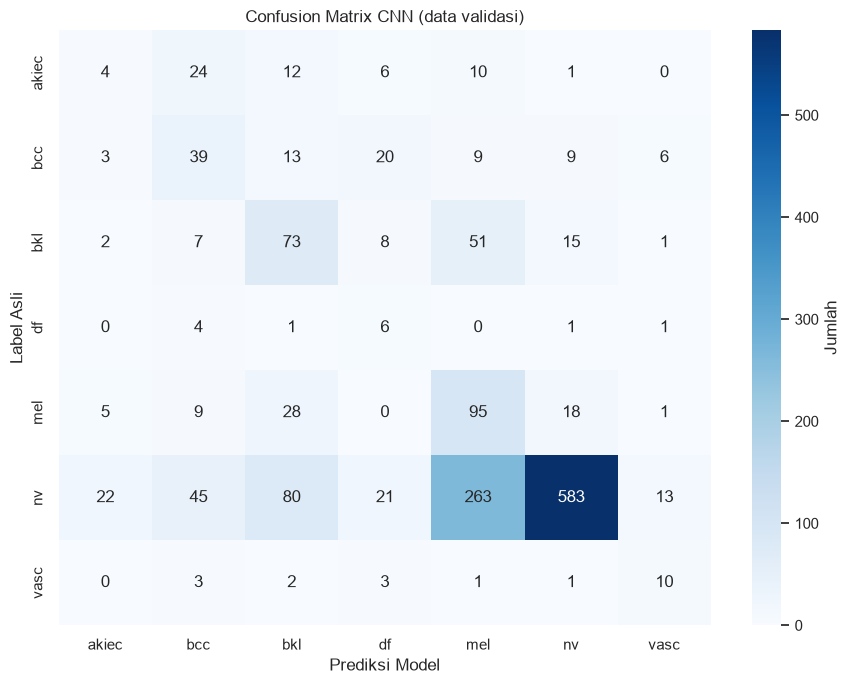

In [10]:
best_cnn = model_gap if winner["model"].endswith("GAP") else model_flat

# Di Keras 3 model Sequential tidak punya `predict_proba`.
# E.predict_with_proba memakai `predict` (output softmax = probabilitas)
# dan memverifikasi jumlah tiap baris = 1.
y_pred_val, y_proba_val = E.predict_with_proba(best_cnn, val_ds, val_steps)
y_val = df_val["dx_idx"].to_numpy()

res_cnn = E.evaluate_model(y_val, y_pred_val, y_proba_val)
E.print_report(res_cnn, "CNN TERPILIH - EVALUASI DI DATA VALIDASI")

E.plot_confusion_matrix(
    y_val, y_pred_val,
    title="Confusion Matrix CNN (data validasi)",
    save_path=C.DOCS_ASSETS / "cnn_05_confusion_matrix.png",
)


## Bagian 10: Analisis Error - Contoh Prediksi Salah

**Ini bagian yang paling bernilai untuk presentasi.** Metrik angka
memberi tahu "berapa banyak salah", tapi contoh gambarnya memberi tahu
"KENAPA salah".

Kita fokus pada **`mel` (melanoma)**: lesi ganas yang lolos diprediksi
sebagai kelas lain. Ini kesalahan paling berbahaya untuk aplikasi
skrining.


Contoh prediksi salah untuk kelas 'mel': 61 dari 156


Contoh error disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\docs\assets\cnn_06_error_melanoma.png


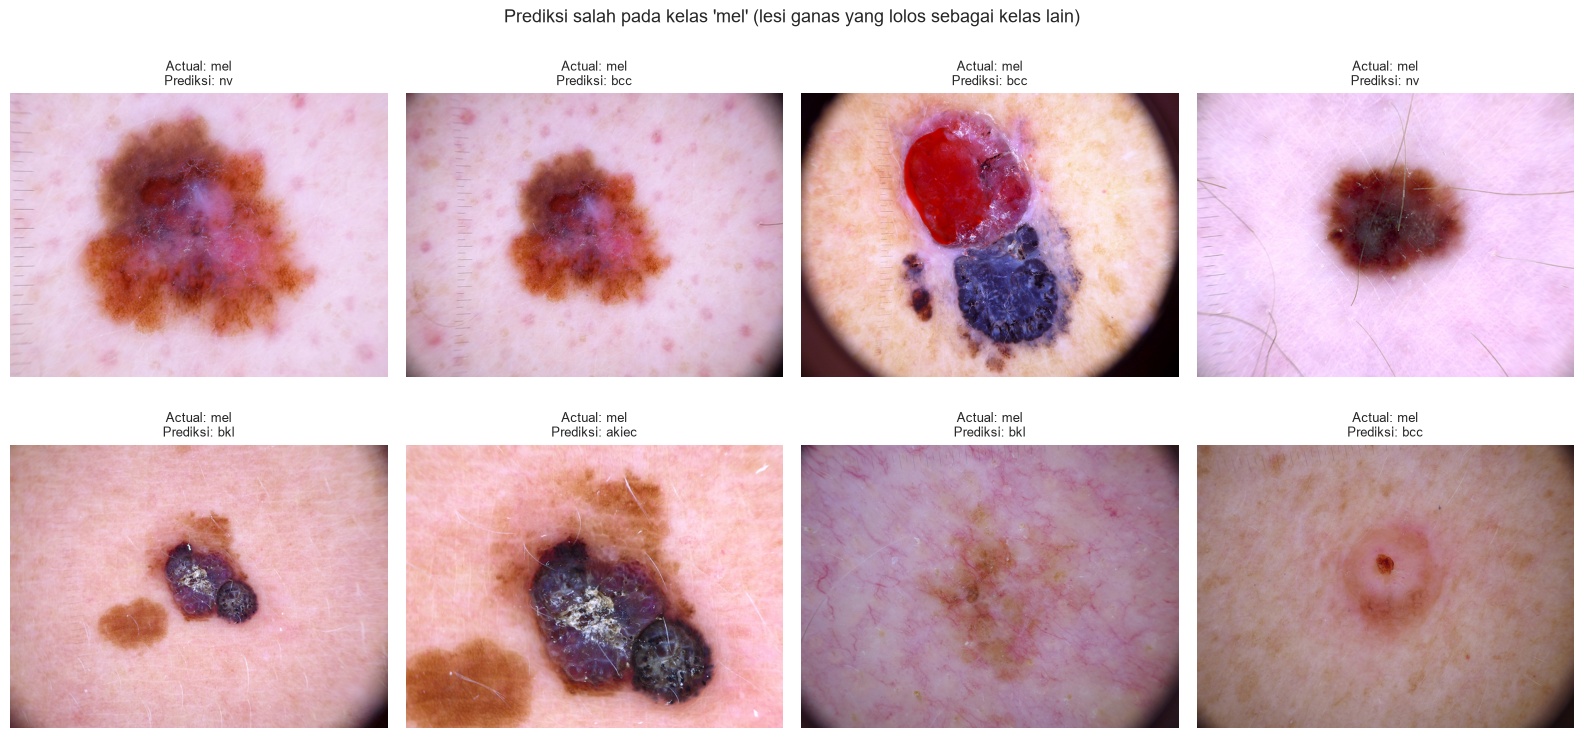

In [11]:
E.plot_error_analysis(
    y_val, y_pred_val,
    image_paths=df_val["image_path"].tolist(),
    class_names=C.CLASSES,
    n_examples=8,
    focus_class="mel",
    save_path=C.DOCS_ASSETS / "cnn_06_error_melanoma.png",
)


**Interpretasi Bagian 10:**

**Apa yang biasanya membuat melanoma salah diklasifikasi:**

1. **Melanoma ganas tapi sangat pigmented** sehingga terlihat seperti
   mola biasa. Ini kasus tersulit, dan memang_limitasi nyata model.
2. **Melanoma incipient** (kanker stadium awal) yang belum berkembang,
   jadi cirinya belum jelas.
3. **Gambar dengan pencahayaan atausudut yang tidak ideal**, yang
   mengubah warna lesi.

**Kenapa ini penting untuk laporan:** kita menunjukkan bahwa kesalahan
TIDAK acak, tapi terjadi pada kasus klinis yang memang sulit. Ini
menunjukkan pemahaman, bukan sekadar angka.

**Catatan jujur:** kalau jumlah melanoma yang salah di validasi sangat
sedikit, tabel ini akan kosong. Itu hasil yang baik, dan kita akan
mengatakannya apa adanya.


## Bagian 11: Menyimpan Model CNN

Kita menyimpan model **bersama** konfigurasi preprocessing-nya, supaya
aplikasi web tidak bisa salah preprocessing.


In [12]:
modeling.save_model(
    best_cnn,
    run_name="cnn_best",
    extra_config={
        "model_type": "cnn_from_scratch",
        "global_average_pooling": bool("GAP" in winner["model"]),
        "img_size": C.IMG_SIZE_CNN,
        "normalization": "rescaling_1_255",
        "epochs_trained": len(
            (history_gap if "GAP" in winner["model"] else history_flat)
            .history["loss"]
        ),
        "validation_f1_macro": winner["f1_macro"],
        "validation_malignant_recall": winner["malignant_recall"],
    },
)


Model disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\models\cnn_best.keras (25.3 MB)
Label map disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\models\label_map.json
Config preprocessing disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\models\preprocess_config.json


WindowsPath('M:/GrenPlums Roses/Program32bit/Forestrypansy/ML2026_Kelas_3_Kelompok_1_LesiKulit/models/cnn_best.keras')

## Bagian 12: Ringkasan dan Langkah Berikutnya

**Yang sudah dilakukan:**
- Pipeline `tf.data` yang hemat memori (tidak muat semua gambar ke RAM)
- Visualisasi augmentasi (supaya bisa ditunjukkan saat presentasi)
- Analisis jumlah parameter GAP vs Flatten (dihitung dari kode)
- Training CNN dengan class weight + EarlyStopping
- **Eksperimen wajib:** GAP vs Flatten dengan setting identik
- Diagnosis overfitting/underfitting dari kurva training
- Confusion matrix + analisis error pada melanoma
- Model + config preprocessing disimpan

**Angka kunci (akan dibandingkan di Notebook 07):**
- Best variant : {winner['model']}
- Parameter     : {winner['params']:,}
- F1 macro      : {winner['f1_macro']:.4f}
- Recall ganas  : {winner['malignant_recall']:.4f}

**Langkah berikutnya (Fase 6):** transfer learning MobileNetV2 di
`06_mobilenetv2.ipynb`, dengan tahap 1 (backbone beku) dan tahap 2
(fine-tuning sebagian lapisan atas + augmentasi gaya smartphone).


In [13]:
summary_cnn = {
    "model": winner["model"],
    "params": winner["params"],
    "f1_macro": winner["f1_macro"],
    "accuracy": winner["accuracy"],
    "malignant_recall": winner["malignant_recall"],
    "epochs_trained": winner["epochs_trained"],
    "best_val_loss": winner["best_val_loss"],
    "gap_vs_flatten": perbandingan,
    "diagnosis": diagnosis,
}
out = C.REPO_ROOT / "docs" / "logs" / "model_cnn_validasi.json"
out.parent.mkdir(parents=True, exist_ok=True)
with open(out, "w", encoding="utf-8") as f:
    json.dump(summary_cnn, f, indent=2, ensure_ascii=False)
print(f"Ringkasan CNN disimpan: {out}")
print("\nNotebook 05 selesai.")


Ringkasan CNN disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\docs\logs\model_cnn_validasi.json

Notebook 05 selesai.
